# SHAP explainability analysis

This notebook orchestrates reusable SHAP functions from `icare_risk.explainability`. It explains fitted models on the temporal test set. SHAP describes model behaviour; it does not establish causality.

In [11]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [12]:
from pathlib import Path
import joblib
import matplotlib.pyplot as plt
import pandas as pd
import yaml
from IPython.display import display

from icare_risk.data.audit import load_admission_file
from icare_risk.models.training import encode_binary_target
from icare_risk.explainability import (
    calculate_shap_values,
    shap_importance_table,
    shap_values_table,
)

CONFIG_PATH = Path('../src/icare_risk/config/icare/analysis.yaml')
with CONFIG_PATH.open() as f:
    config = yaml.safe_load(f)

df = load_admission_file(config['outputs']['processed_dataset'])
target = config['columns']['target']
test = df.loc[df['split'].eq('test')].copy()
mapping = config.get('target_mapping', {})
test['__binary_target__'] = encode_binary_target(
    test[target],
    positive_values=mapping.get('positive_values'),
    negative_values=mapping.get('negative_values'),
)
test = test.dropna(subset=['__binary_target__'])
y_test = test['__binary_target__'].astype(int)

max_rows = config.get('explainability', {}).get('shap_max_rows', 2000)
if len(test) > max_rows:
    test = test.sample(max_rows, random_state=42)
    y_test = test['__binary_target__'].astype(int)
print(f'SHAP rows: {len(test):,}; events: {y_test.sum():,}')

SHAP rows: 2,000; events: 406


In [13]:
model_directory = Path(config['outputs']['model_directory'])
fitted_models = {}
feature_map = {}
for model_cfg in config['models']:
    name = model_cfg['name']
    bundle = joblib.load(model_directory / f'{name}.joblib')
    fitted_models[name] = bundle['model']
    feature_map[name] = bundle['features']
print('Available models:', list(fitted_models))

Available models: ['lr_kim_score', 'lr_all_scores', 'lr_clinical_baseline', 'xgb_kim_score', 'xgb_all_scores', 'xgb_clinical_baseline']


In [14]:
output_directory = Path(config['outputs'].get('shap_directory', 'results/feature_importance/shap'))
output_directory.mkdir(parents=True, exist_ok=True)
global_tables = []
individual_tables = []
shap_results = {}

for name, model in fitted_models.items():
    features = feature_map[name]
    X_test = test[features]
    print(f'Calculating SHAP values for {name} ({len(X_test):,} rows, {len(features)} raw features)...')
    values, transformed_names = calculate_shap_values(model, X_test)
    shap_results[name] = (values, transformed_names)
    global_table = shap_importance_table(values, transformed_names, model_name=name)
    global_tables.append(global_table)
    row_table = shap_values_table(values, transformed_names, index=X_test.index)
    row_table.insert(0, 'model', name)
    row_table.insert(1, 'admission_index', X_test.index)
    individual_tables.append(row_table)
    global_table.to_csv(output_directory / f'{name}_global_importance.csv', index=False)

global_importance = pd.concat(global_tables, ignore_index=True)
shap_values = pd.concat(individual_tables, ignore_index=True)
global_importance.to_csv(output_directory / 'shap_global_importance.csv', index=False)
shap_values.to_parquet(output_directory / 'shap_values.parquet', index=False)
display(global_importance.groupby('model', group_keys=False).head(20))

Calculating SHAP values for lr_kim_score (2,000 rows, 5 raw features)...
Calculating SHAP values for lr_all_scores (2,000 rows, 6 raw features)...
Calculating SHAP values for lr_clinical_baseline (2,000 rows, 16 raw features)...
Calculating SHAP values for xgb_kim_score (2,000 rows, 5 raw features)...
Calculating SHAP values for xgb_all_scores (2,000 rows, 6 raw features)...
Calculating SHAP values for xgb_clinical_baseline (2,000 rows, 16 raw features)...


,model,feature,mean_abs_shap,mean_shap,importance_rank
0,lr_kim_score,numeric__kim_hx_prior_esbl,0.017154,0.010334,1
1,lr_kim_score,numeric__kim_hx_prior_antibiotics_90d,0.009070,-0.002333,2
2,lr_kim_score,numeric__kim_hx_recent_hosp_1yr,0.000000,0.000000,3
3,lr_kim_score,numeric__kim_hx_nursing_home_resident,0.000000,0.000000,4
4,lr_kim_score,numeric__kim_hx_urinary_catheter,0.000000,0.000000,5
...,...,...,...,...,...
70,xgb_clinical_baseline,categorical__INDEX_OF_MULTIPLE_DEPRIVATION_DEC...,0.011393,-0.001063,16
71,xgb_clinical_baseline,categorical__MAIN_SPECIALTY_CODE_DESC_gastroen...,0.011242,0.000587,17
72,xgb_clinical_baseline,categorical__INDEX_OF_MULTIPLE_DEPRIVATION_DEC...,0.011022,0.000440,18
73,xgb_clinical_baseline,categorical__INDEX_OF_MULTIPLE_DEPRIVATION_DEC...,0.009720,-0.000174,19


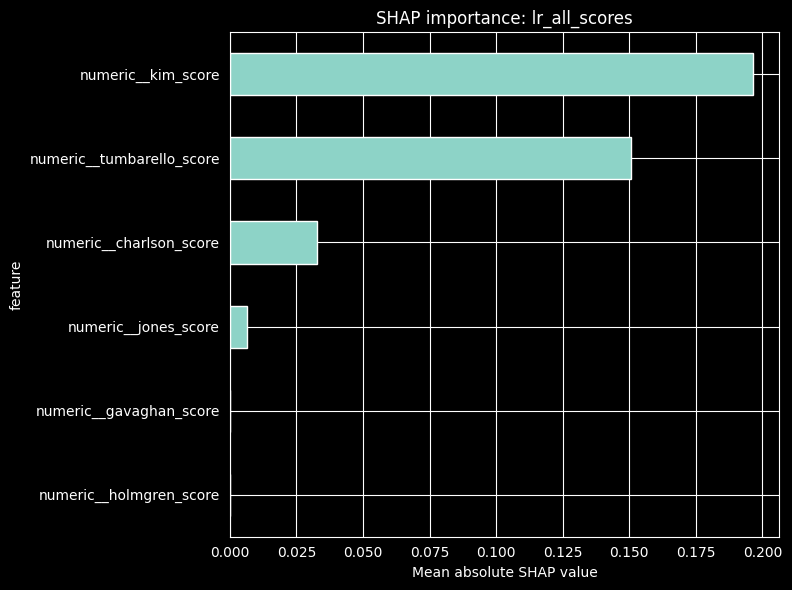

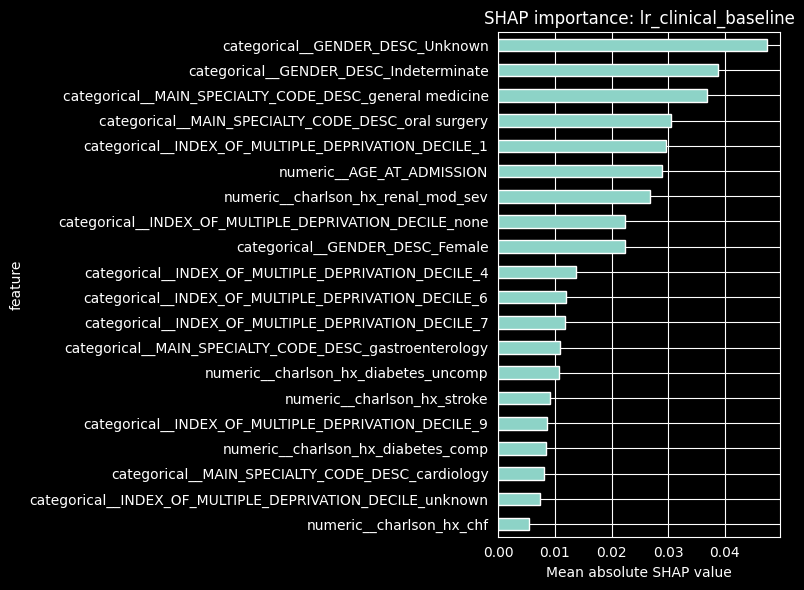

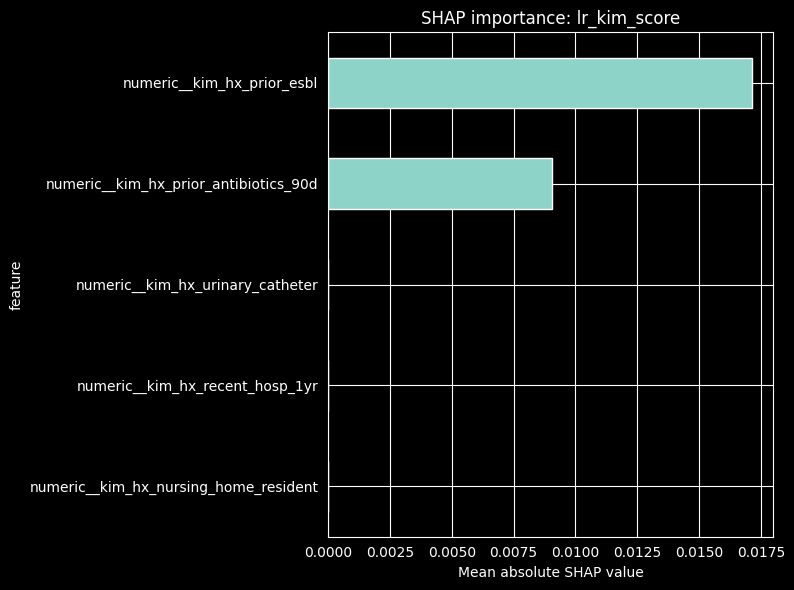

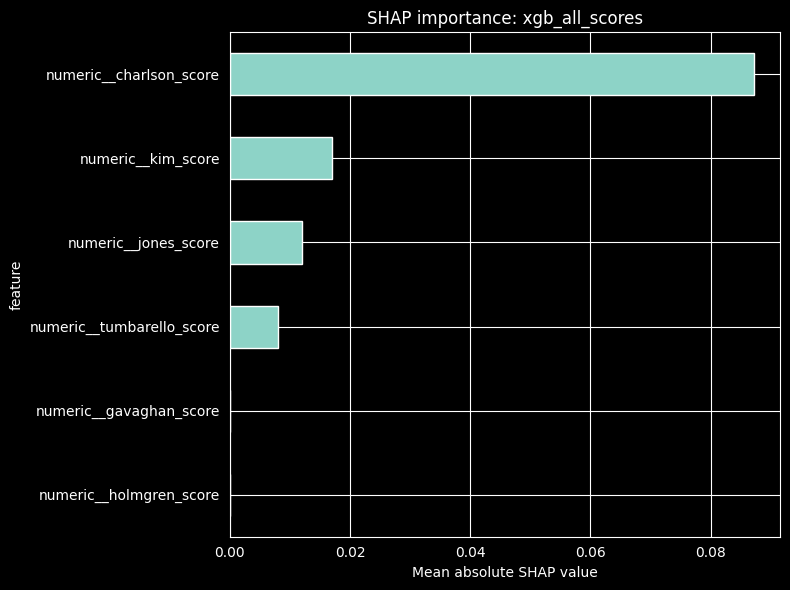

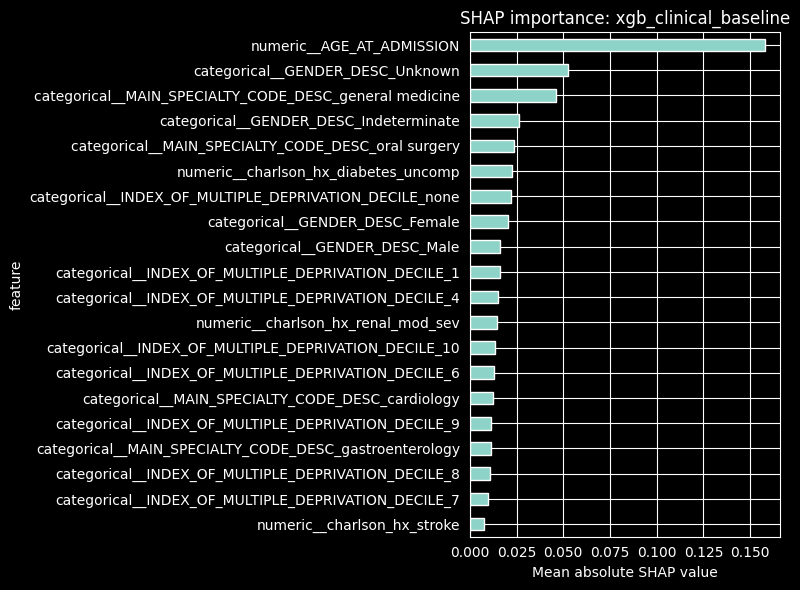

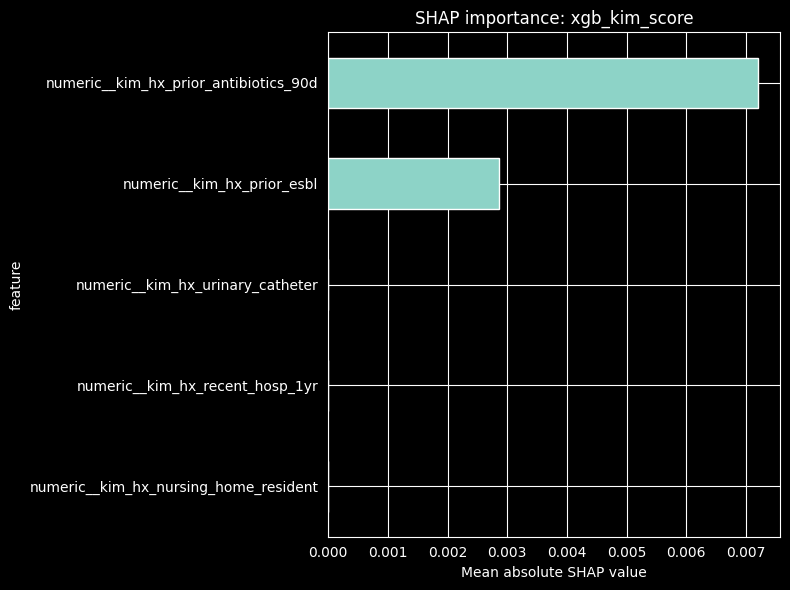

In [15]:
# Simple reusable-notebook plots for the top features of each model.
for name, group in global_importance.groupby('model'):
    top = group.nlargest(20, 'mean_abs_shap').sort_values('mean_abs_shap')
    ax = top.plot.barh(x='feature', y='mean_abs_shap', legend=False, figsize=(8, 6), title=f'SHAP importance: {name}')
    ax.set_xlabel('Mean absolute SHAP value')
    plt.tight_layout()
    plt.savefig(output_directory / f'{name}_shap_importance.png', dpi=200)
    plt.show()